## 1. Data Exploration (EDA)

In [1]:
from pathlib import Path
base_dir=Path("/kaggle/input/competitions/recodai-luc-scientific-image-forgery-detection")
print("Top level contents",[p.name for p in base_dir.iterdir()])

Top level contents ['sample_submission.csv', 'train_images', 'supplemental_masks', 'train_masks', 'supplemental_images', 'test_images']


In [2]:
auth_dir=Path("/kaggle/input/competitions/recodai-luc-scientific-image-forgery-detection/train_images/authentic")
forged_dir=Path("/kaggle/input/competitions/recodai-luc-scientific-image-forgery-detection/train_images/forged")
mask_dir=Path("/kaggle/input/competitions/recodai-luc-scientific-image-forgery-detection/train_masks")

In [3]:
auth_files=sorted(auth_dir.glob("*"))
forged_files=sorted(forged_dir.glob("*"))
masked_files=sorted(mask_dir.glob("*.npy"))
print(f"Authentic images:{len(auth_files)}")
print(f"Forged images:{len(forged_files)}")
print(f"Masked files(.npy):{len(masked_files)}")
print(f"Sample forged image: {forged_files[4].name}")
print(f"Sample masked image: {masked_files[4].name}")

Authentic images:2377
Forged images:2751
Masked files(.npy):2751
Sample forged image: 10070.png
Sample masked image: 10070.npy


Image shape: (712, 414, 3)
Mask Shape (2, 712, 414)
Mask dtype uint8
Unique mask value [0 1]


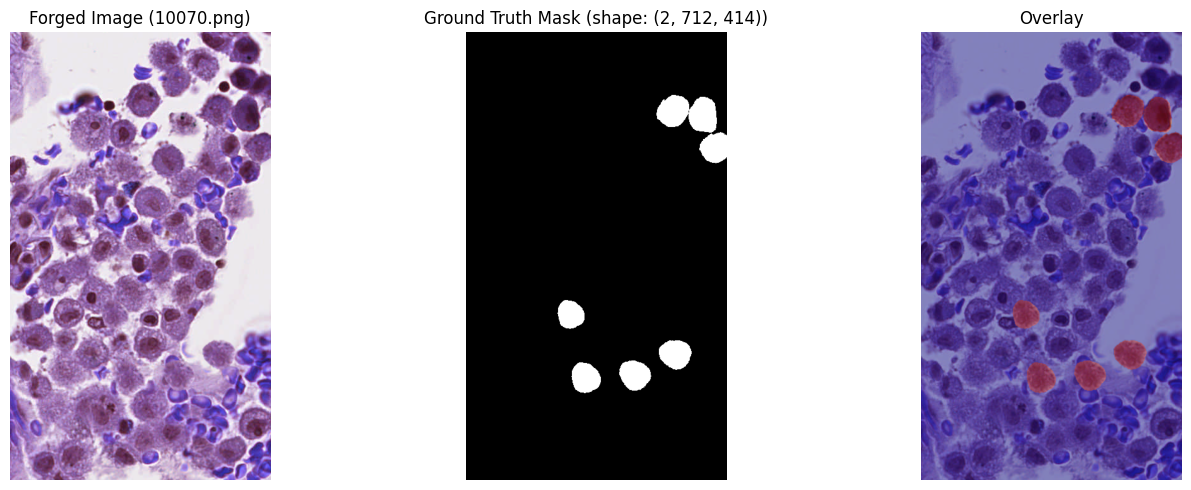

In [4]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
img_path=forged_files[4]
mask_path=mask_dir/f"{img_path.stem}.npy"
img=np.array(Image.open(img_path).convert("RGB"))
mask=np.load(mask_path)
print("Image shape:",img.shape)
print("Mask Shape",mask.shape)
print("Mask dtype",mask.dtype)
print("Unique mask value",np.unique(mask))

mask_2d=mask.max(axis=0) if mask.ndim==3 else mask
fig,axes =plt.subplots(1,3,figsize=(15,5))

axes[0].imshow(img)
axes[0].set_title(f"Forged Image ({img_path.name})")
axes[0].axis("off")

axes[1].imshow(mask_2d,cmap="gray")
axes[1].set_title(f"Ground Truth Mask (shape: {mask.shape})")
axes[1].axis("off")

axes[2].imshow(img) 
axes[2].imshow(mask_2d>0,cmap="jet",alpha=0.45)
axes[2].set_title("Overlay")
axes[2].axis("off")
plt.tight_layout()
plt.show()


In [5]:
import pandas as pd
records=[]
for img_path in auth_files:
    with Image.open(img_path) as im:
        w,h=im.size
        records.append({
            "case_id":img_path.stem,
            "image_path":str(img_path),
            "mask_path":"",
            "label":0,
            "width":w,
            "height":h,
            "n_regions":0,
            "forged_ratio":0.0
        })
for img_path in forged_files:
    with Image.open(img_path) as im:
        w,h=im.size
    m_path=mask_dir/f"{img_path.stem}.npy"
    mask=np.load(m_path)

    n_regions=mask.shape[0] if mask.ndim==3 else 1
    mask_2d=mask.max(axis=0) if mask.ndim==3 else mask
    forged_ratio=float((mask_2d>0).mean())
    records.append({
        "case_id":img_path.stem,
        "image_path":str(img_path),
        "mask_path":str(m_path),
        "label":1,
        "width":w,
        "height":h,
        "n_regions":n_regions,
        "forged_ratio":forged_ratio
    })
df=pd.DataFrame(records)

print(f"Total images indexed: {len(df)}")
print("\n Top 5 Most common Image sizes (Width x Height)")
print(df.groupby(["width","height"]).size().sort_values(ascending=False).head(5))

print("\n Number of forged regions per forged image")
print(df[df["label"]==1]["n_regions"].value_counts().sort_index())

print("\n Forged pixel area% of forged image")
print((df[df["label"]==1]["forged_ratio"]*100).describe().round(2))
print(df.isnull().sum())

Total images indexed: 5128

 Top 5 Most common Image sizes (Width x Height)
width  height
1000   666       686
256    256       605
1600   1200      530
696    520       256
320    256       229
dtype: int64

 Number of forged regions per forged image
n_regions
1    1869
2     701
3     174
4       5
5       2
Name: count, dtype: int64

 Forged pixel area% of forged image
count    2751.00
mean        5.52
std         6.92
min         0.04
25%         0.75
50%         2.71
75%         8.09
max        52.27
Name: forged_ratio, dtype: float64
case_id         0
image_path      0
mask_path       0
label           0
width           0
height          0
n_regions       0
forged_ratio    0
dtype: int64


## 2. Dataset Splitting

In [6]:
from sklearn.model_selection import StratifiedGroupKFold

def get_visual_hash(img_path):
    with Image.open(img_path) as im:
        small=im.convert("L").resize((8,8))
        pixels=np.asarray(small,dtype=np.float32)
        bits=(pixels>pixels.mean()).flatten()
        return "".join("1" if b else "0" for b in bits)
df["visual_hash"]=[get_visual_hash(p) for p in df["image_path"]]
dus_groups=df.groupby("visual_hash").filter(lambda g: len(g)>1)
print(f"Near duplication visual groups found: {dus_groups["visual_hash"].nunique()} ({len(dus_groups)} images)")

df["size_bin"]=pd.qcut(df["forged_ratio"],q=4,labels=False,duplicates="drop")
df["strat_key"]=df["label"].astype(str)+"_"+df["size_bin"].astype(str)

sgkf=StratifiedGroupKFold(n_splits=6,shuffle=True,random_state=42)
df["fold"]= -1
for fold_num, (_,val_idx) in enumerate(sgkf.split(df,df["strat_key"],groups=df["visual_hash"])):
    df.loc[val_idx,"fold"]=fold_num
fold_to_split={0:"test",1:"val",2:"train",3:"train",4:"train",5:"train"}
df["split"]=df["fold"].map(fold_to_split)
df.drop(columns=["size_bin","strat_key","fold"]).to_csv("/kaggle/working/dataset_split.csv", index=False)
print("Final Split Breakdown (0 = Authentic, 1 = Forged)")
print(pd.crosstab(df["split"],df["label"],margins=True))

Near duplication visual groups found: 582 (1278 images)
Final Split Breakdown (0 = Authentic, 1 = Forged)
label     0     1   All
split                  
test    394   459   853
train  1592  1839  3431
val     391   453   844
All    2377  2751  5128


## 3. Evaluation Metrics

In [7]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,roc_auc_score
def compute_pixel_metrics(pred_mask,true_mask):
    pred=(pred_mask>0).astype(np.float32)
    true=(true_mask>0).astype(np.float32)
    if true.sum()==0:
        score=1.0 if pred.sum()==0 else 0.0
        return score,score
    intersection=(pred*true).sum()
    dice=(2.0*intersection)/(pred.sum() + true.sum()+1e-7)
    union=pred.sum()+true.sum()-intersection
    iou=intersection/(union+1e-7)
    return float(dice),float(iou)

def compute_image_met(y_true,y_prob,threshold=0.5):
    y_pred=(np.array(y_prob)>=threshold).astype(int)
    return {
        "Accuracy":round(accuracy_score(y_true,y_pred),4),
        "Precision":round(precision_score(y_true,y_pred,zero_division=0),4),
        "Recall":round(recall_score(y_true,y_pred,zero_division=0),4),
        "F1":round(f1_score(y_true,y_pred,zero_division=0),4),
        "ROC_AUC":round(roc_auc_score(y_true,y_prob),4)
    }
true_forged=np.array([[0,0,0,0],
                      [0,1,1,0],
                      [0,1,1,0],
                      [0,0,0,0]])
pred_perfect=true_forged.copy()
pred_half=np.array([[0,0,0,0],
                   [0,1,0,0],
                   [0,1,0,0],
                   [0,0,0,0]])
pred_empty=np.zeros((4,4))
print("1. Perfect match on forged image :", compute_pixel_metrics(pred_perfect, true_forged))
print("2. Half overlap on forged image  :", compute_pixel_metrics(pred_half, true_forged))
print("3. Missed forgery (all zeros)    :", compute_pixel_metrics(pred_empty, true_forged))
print("4. Authentic image, correct empty:", compute_pixel_metrics(pred_empty, pred_empty))
print("5. Authentic image, false alarm  :", compute_pixel_metrics(pred_half, pred_empty))

1. Perfect match on forged image : (1.0, 1.0)
2. Half overlap on forged image  : (0.6666666865348816, 0.5)
3. Missed forgery (all zeros)    : (0.0, 0.0)
4. Authentic image, correct empty: (1.0, 1.0)
5. Authentic image, false alarm  : (0.0, 0.0)


## 4. PyTorch Dataset & DataLoader

In [8]:
import torch
from torch.utils.data import Dataset,DataLoader

IMAGENET_MEAN=np.array([0.485,0.456,0.406],dtype=np.float32)
IMAGENET_STD=np.array([0.229,0.224,0.225],dtype=np.float32)
class ForgeryDataset(Dataset):
    def __init__(self,dataframe,img_size=256):
        self.df=dataframe.reset_index(drop=True)
        self.img_size=img_size
    def __len__(self):
        return len(self.df)
    def __getitem__(self,idx):
        row=self.df.iloc[idx]
        img=Image.open(row["image_path"]).convert("RGB")
        img=img.resize((self.img_size,self.img_size),Image.Resampling.BILINEAR)

        img=np.asarray(img,dtype=np.float32)/255.0
        img=(img-IMAGENET_MEAN)/IMAGENET_STD

        img=np.transpose(img,(2,0,1))
        img_tensor=torch.tensor(img,dtype=torch.float32)

        if row["label"] == 0 or not row["mask_path"]:
            mask_2d=np.zeros((self.img_size,self.img_size),dtype=np.float32)
        else:
            mask=np.load(row["mask_path"])
            mask_2d=mask.max(axis=0) if mask.ndim==3 else mask
            mask_2d=(mask_2d>0).astype(np.uint8)
            
            mask_pil=Image.fromarray(mask_2d)
            mask_pil=mask_pil.resize((self.img_size,self.img_size),Image.Resampling.NEAREST)
            mask_2d=np.asarray(mask_pil,dtype=np.float32)
        mask_tensor=torch.tensor(mask_2d,dtype=torch.float32).unsqueeze(0)
        label_tensor=torch.tensor(row["label"],dtype=torch.float32)
        return img_tensor,mask_tensor,label_tensor

train_df=df[df["split"]=="train"]
val_df=df[df["split"]=="val"]
test_df=df[df["split"]=="test"]

train_dataset=ForgeryDataset(train_df,img_size=256)
val_dataset=ForgeryDataset(val_df,img_size=256)
test_dataset=ForgeryDataset(test_df,img_size=256)

train_loader=DataLoader(train_dataset,batch_size=16,shuffle=True,num_workers=2)
val_loader=DataLoader(val_dataset,batch_size=16,shuffle=False,num_workers=2)
test_loader=DataLoader(test_dataset,batch_size=16,shuffle=False,num_workers=2)

images,masks,labels=next(iter(train_loader))
print("Image batch sample: ",images.shape)
print("Masks batch sample: ",masks.shape)
print("Labels batch sample: ",labels.shape)
print("Unique mask values: ",torch.unique(masks))

Image batch sample:  torch.Size([16, 3, 256, 256])
Masks batch sample:  torch.Size([16, 1, 256, 256])
Labels batch sample:  torch.Size([16])
Unique mask values:  tensor([0., 1.])


## 5. Open-Source Baseline Model

In [9]:

import torch
import torch.nn as nn
import torch.nn.functional as F
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device: ",device)

IMG_SIZE=224
train_loader=DataLoader(ForgeryDataset(train_df,img_size=IMG_SIZE),batch_size=16,shuffle=True,num_workers=2)
val_loader=DataLoader(ForgeryDataset(val_df,img_size=IMG_SIZE),batch_size=16,shuffle=False,num_workers=2)
test_loader=DataLoader(ForgeryDataset(test_df,img_size=IMG_SIZE),batch_size=16,shuffle=False,num_workers=2)

class BaselineDINOv2(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder=torch.hub.load("facebookresearch/dinov2","dinov2_vits14")
        for param in self.encoder.parameters():
            param.requires_grad=False
        self.decoder=nn.Sequential(
            nn.Conv2d(384,128,kernel_size=3,padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(128,64,kernel_size=3,padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(64,1,kernel_size=1)
        )
    def forward(self,x):
        B,C,H,W=x.shape

        with torch.no_grad():
            features=self.encoder.forward_features(x)["x_norm_patchtokens"]
        grid_h,grid_w=H//14,W//14
        feat_map=features.permute(0,2,1).reshape(B,384,grid_h,grid_w)
        logits=self.decoder(feat_map)
        logits=F.interpolate(logits,size=(H,W),mode="bilinear",align_corners=False)
        return logits
model=BaselineDINOv2().to(device)

sample_imgs,sample_masks,sample_labels=next(iter(train_loader))
sample_imgs=sample_imgs.to(device)

with torch.no_grad():
    output_logits=model(sample_imgs)
print("Input image shape: ",sample_imgs.shape)
print("Output image shape: ",output_logits.shape)

Using device:  cuda
Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 484MB/s]


Input image shape:  torch.Size([16, 3, 224, 224])
Output image shape:  torch.Size([16, 1, 224, 224])


In [10]:
import time

criterion=nn.BCEWithLogitsLoss()

optimizer=torch.optim.AdamW(model.decoder.parameters(),lr=1e-3)

def train_one_epoch(model,loader,optimizer,criterion):
    model.train()
    total_loss=0.0

    for imgs,masks,_ in loader:
        imgs=imgs.to(device)
        masks=masks.to(device)

        optimizer.zero_grad()
        logits=model(imgs)
        loss=criterion(logits,masks)
        loss.backward()
        optimizer.step()

        total_loss+=loss.item()

    return total_loss/len(loader)

def evaluate(model,loader,criterion):
    model.eval()
    total_loss=0.0
    all_dice,all_iou=[],[]
    all_y_true,all_y_prob=[],[]


    with torch.no_grad():
        for imgs,masks,labels in loader:
            imgs=imgs.to(device)
            masks=masks.to(device)

            logits=model(imgs)
            loss=criterion(logits,masks)
            total_loss+=loss.item()

            probs=torch.sigmoid(logits).squeeze(1).cpu().numpy()
            true_masks=masks.squeeze(1).cpu().numpy()

            for i in range(len(probs)):
                pred_bin=(probs[i]>=0.5).astype(np.float32)
                d,iou=compute_pixel_metrics(pred_bin,true_masks[i])
                all_dice.append(d)
                all_iou.append(iou)

                all_y_prob.append(float(probs[i].max()))
                all_y_true.append(int(labels[i].item()))

    img_scores=compute_image_met(all_y_true,all_y_prob,threshold=0.5)
    return {
        "loss":round(total_loss/len(loader),4),
        "dice":round(float(np.mean(all_dice)),4),
        "iou":round(float(np.mean(all_iou)),4),
        **img_scores
    }

EPOCHS=10
best_dice=-1.0

for epoch in range(1,EPOCHS+1):
    start=time.time()
    train_loss=train_one_epoch(model,train_loader,optimizer,criterion)
    val_metrice=evaluate(model,val_loader,criterion)
    elapsed=time.time()-start

    print({
        f"Epoch {epoch}/{EPOCHS} ({elapsed:.0f}s) |"
        f"Training Loss: {train_loss:.4f} | Val loss: {val_metrice["loss"]:.4f} |"
        f"Val Dice: {val_metrice["dice"]:.4f} | Val IoU: {val_metrice["iou"]:.4f} |"
        f"Img F1: {val_metrice["F1"]:.4f} | AUC: {val_metrice["ROC_AUC"]:.4f}"
    })
    if val_metrice["dice"]>best_dice:
        best_dice=val_metrice["dice"]
        torch.save(model.state_dict(),"/kaggle/working/baseline_best.pth")
        print("Saved best new baseline checkpoint ")

{'Epoch 1/10 (110s) |Training Loss: 0.1061 | Val loss: 0.0924 |Val Dice: 0.4617 | Val IoU: 0.4603 |Img F1: 0.1829 | AUC: 0.5761'}
Saved best new baseline checkpoint 
{'Epoch 2/10 (109s) |Training Loss: 0.0926 | Val loss: 0.0946 |Val Dice: 0.4578 | Val IoU: 0.4550 |Img F1: 0.2089 | AUC: 0.6036'}
{'Epoch 3/10 (114s) |Training Loss: 0.0873 | Val loss: 0.0882 |Val Dice: 0.4408 | Val IoU: 0.4229 |Img F1: 0.3851 | AUC: 0.5508'}
{'Epoch 4/10 (108s) |Training Loss: 0.0839 | Val loss: 0.0895 |Val Dice: 0.4505 | Val IoU: 0.4288 |Img F1: 0.4481 | AUC: 0.5975'}
{'Epoch 5/10 (108s) |Training Loss: 0.0818 | Val loss: 0.0856 |Val Dice: 0.4856 | Val IoU: 0.4721 |Img F1: 0.3148 | AUC: 0.5914'}
Saved best new baseline checkpoint 
{'Epoch 6/10 (110s) |Training Loss: 0.0797 | Val loss: 0.0854 |Val Dice: 0.4603 | Val IoU: 0.4393 |Img F1: 0.4384 | AUC: 0.5788'}
{'Epoch 7/10 (112s) |Training Loss: 0.0765 | Val loss: 0.0837 |Val Dice: 0.4563 | Val IoU: 0.4330 |Img F1: 0.4572 | AUC: 0.6017'}
{'Epoch 8/10 (115s

In [11]:
model.load_state_dict(torch.load("/kaggle/working/baseline_best.pth",map_location=device))
def evaluate_detailed(model,loader,exp_name,threshold=0.5):
    model.eval()
    all_dice,all_iou=[],[]
    forged_dice,forged_iou=[],[]
    auth_correct,auth_total=0,0
    all_y_true,all_y_prob=[],[]

    with torch.no_grad():
        for imgs,masks,labels in loader:
            imgs=imgs.to(device)
            logits=model(imgs)
            probs=torch.sigmoid(logits).squeeze(1).cpu().numpy()
            true_masks=masks.squeeze(1).cpu().numpy()

            for i in range(len(probs)):
                pred_bin=(probs[i]>=threshold).astype(np.float32)
                d,iou=compute_pixel_metrics(pred_bin,true_masks[i])
                all_dice.append(d)
                all_iou.append(iou)

                label=int(labels[i].item())
                if label ==1:
                    forged_dice.append(d)
                    forged_iou.append(iou)
                else:
                    auth_total+=1
                    if pred_bin.sum()==0:
                        auth_correct+=1
                all_y_true.append(label)
                all_y_prob.append(float(probs[i].max()))
    img_scores=compute_image_met(all_y_true,all_y_prob,threshold=threshold)
    summary={
        "Experiment":exp_name,
        "Overall_Dice":round(float(np.mean(all_dice)),4),
        "Forged_Dice":round(float(np.mean(forged_dice)),4),
        "Forged_IoU":round(float(np.mean(forged_iou)),4),
        "Auth_Clean%":round(100.0*auth_correct/max(auth_total,1),2),
        "Img_F1":img_scores["F1"],
        "Img_AUC":img_scores["ROC_AUC"]
        
    }
    return summary
result_log=[]
baseline_test=evaluate_detailed(model,test_loader,exp_name="01_Baseline_DINOv2_224_BCE")
result_log.append(baseline_test)
pd.DataFrame(result_log)

,Experiment,Overall_Dice,Forged_Dice,Forged_IoU,Auth_Clean%,Img_F1,Img_AUC
0,01_Baseline_DINOv2_224_BCE,0.5058,0.1121,0.0764,96.45,0.4181,0.6056


## 6. Model Modifications

In [12]:
IMG_SIZE_MOD=336
train_loader_mod=DataLoader(ForgeryDataset(train_df,img_size=IMG_SIZE_MOD),batch_size=16,shuffle=True,num_workers=2)
val_loader_mod=DataLoader(ForgeryDataset(val_df,img_size=IMG_SIZE_MOD),batch_size=16,shuffle=False,num_workers=2)
test_loader_mod=DataLoader(ForgeryDataset(test_df,img_size=IMG_SIZE_MOD),batch_size=16,shuffle=False,num_workers=2)

class BCEDiceLoss(nn.Module):
    def __init__(self,bce_weight=0.5,dice_weight=0.5):
        super().__init__()
        self.bce=nn.BCEWithLogitsLoss()
        self.bce_weight=bce_weight
        self.dice_weight=dice_weight
    def forward(self,logits,targets):
        bce_loss=self.bce(logits,targets)

        probs=torch.sigmoid(logits)
        probs_flat=probs.view(probs.size(0),-1)
        target_flat=targets.view(targets.size(0),-1)

        intersection=(probs_flat*target_flat).sum(dim=1)
        dice_score=(2.0*intersection+1.0)/(probs_flat.sum(dim=1)+target_flat.sum(dim=1)+1.0)
        dice_loss=1.0-dice_score.mean()

        return self.bce_weight*bce_loss+self.dice_weight*dice_loss

class SelfSimDINOv2(nn.Module):
    def __init__(self,top_k=8):
        super().__init__()
        self.top_k=top_k

        self.encoder=torch.hub.load("facebookresearch/dinov2", "dinov2_vits14")
        for param in self.encoder.parameters():
            param.requires_grad=False

        self.decoder=nn.Sequential(
            nn.Conv2d(384+top_k,192,kernel_size=3,padding=1),
            nn.BatchNorm2d(192),
            nn.ReLU(inplace=True),
            nn.Conv2d(192,64,kernel_size=3,padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64,1,kernel_size=1)
        )
    def forward(self,x):
        B,C,H,W=x.shape
        grid_h,grid_w=H//14,W//14

        with torch.no_grad():
            features=self.encoder.forward_features(x)["x_norm_patchtokens"]
        norm_feat=F.normalize(features,p=2,dim=-1)
        sim_matrix=torch.bmm(norm_feat,norm_feat.transpose(1,2))
        coords=torch.stack(torch.meshgrid(
            torch.arange(grid_h,device=x.device),
            torch.arange(grid_w,device=x.device),
            indexing="ij"),dim=-1).reshape(-1,2).float()
        dist=torch.cdist(coords,coords)
        neighbor_mask=dist<=2.0
        sim_matrix=sim_matrix.masked_fill(neighbor_mask.unsqueeze(0),-1.0)

        topk_sim,_=torch.topk(sim_matrix,k=self.top_k,dim=-1)

        feat_map=features.permute(0,2,1).reshape(B,384,grid_h,grid_w)
        sim_map=topk_sim.permute(0,2,1).reshape(B,self.top_k,grid_h,grid_w)
        combined=torch.cat([feat_map,sim_map],dim=1)
        logits=self.decoder(combined)
        logits=F.interpolate(logits,size=(H,W),mode="bilinear",align_corners=False)
        return logits

mod_model=SelfSimDINOv2(top_k=8).to(device)
criterion_mod=BCEDiceLoss()

sample_imgs,sample_masks,_=next(iter(train_loader_mod))
sample_imgs,sample_masks=sample_imgs.to(device),sample_masks.to(device)

with torch.no_grad():
    out=mod_model(sample_imgs)
    test_loss=criterion_mod(out,sample_masks)
print("Modified input shape: ",sample_imgs.shape)
print("Modified output shape: ",out.shape)
print("Initial BCE+Dice loss: ",round(test_loss.item(),4))

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


Modified input shape:  torch.Size([16, 3, 336, 336])
Modified output shape:  torch.Size([16, 1, 336, 336])
Initial BCE+Dice loss:  0.8112


In [13]:
EPOCHS_MOD=6
optimizer_mod=torch.optim.AdamW(mod_model.decoder.parameters(),lr=1e-3,weight_decay=1e-4)
scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_mod,T_max=EPOCHS_MOD)

best_dice_mod=-1.0

for epoch in range(1,EPOCHS_MOD+1):
    start=time.time()
    train_loss=train_one_epoch(mod_model,train_loader_mod,optimizer_mod,criterion_mod)
    val_metrice=evaluate(mod_model,val_loader_mod,criterion_mod)
    scheduler.step()
    elapsed=time.time()-start

    print(
        f"Epoch {epoch}/{EPOCHS_MOD} ({elapsed:.0f}s) |"
        f"Train Loss: {train_loss:.4f} | Val loss: {val_metrice["loss"]:.4f} |"
        f"Val Dice: {val_metrice["dice"]:.4f} | Val IoU: {val_metrice["iou"]:.4f} |"
        f"Img F1: {val_metrice["F1"]:.4f} | AUC: {val_metrice["ROC_AUC"]:.4f}"
    )
    if val_metrice["dice"]>best_dice_mod:
        best_dice_mod=val_metrice["dice"]
        torch.save(mod_model.state_dict(),"/kaggle/working/mod1_selfsim_best.pth")
        print("Saved new best Mod #1 checkpoint!")
mod_model.load_state_dict(torch.load("/kaggle/working/mod1_selfsim_best.pth", map_location=device))
mod1_test=evaluate_detailed(mod_model,test_loader_mod,exp_name="02_SelfSim_336_BCEDice")

result_log.append(mod1_test)
pd.DataFrame(result_log)

Epoch 1/6 (126s) |Train Loss: 0.5571 | Val loss: 0.4952 |Val Dice: 0.3521 | Val IoU: 0.3100 |Img F1: 0.6364 | AUC: 0.6330
Saved new best Mod #1 checkpoint!
Epoch 2/6 (126s) |Train Loss: 0.4845 | Val loss: 0.4768 |Val Dice: 0.3165 | Val IoU: 0.2630 |Img F1: 0.7059 | AUC: 0.7207
Epoch 3/6 (128s) |Train Loss: 0.4659 | Val loss: 0.4635 |Val Dice: 0.3254 | Val IoU: 0.2713 |Img F1: 0.7058 | AUC: 0.7396
Epoch 4/6 (127s) |Train Loss: 0.4544 | Val loss: 0.4628 |Val Dice: 0.3430 | Val IoU: 0.2900 |Img F1: 0.7245 | AUC: 0.7732
Epoch 5/6 (126s) |Train Loss: 0.4438 | Val loss: 0.4562 |Val Dice: 0.2940 | Val IoU: 0.2358 |Img F1: 0.7213 | AUC: 0.7817
Epoch 6/6 (124s) |Train Loss: 0.4363 | Val loss: 0.4550 |Val Dice: 0.3175 | Val IoU: 0.2597 |Img F1: 0.7293 | AUC: 0.7921


,Experiment,Overall_Dice,Forged_Dice,Forged_IoU,Auth_Clean%,Img_F1,Img_AUC
0,01_Baseline_DINOv2_224_BCE,0.5058,0.1121,0.0764,96.45,0.4181,0.6056
1,02_SelfSim_336_BCEDice,0.3270,0.2548,0.1770,41.12,0.6097,0.6205


In [14]:
class FineTunedSelfSimDINOv2(SelfSimDINOv2):
    def __init__(self,top_k=8):
        super().__init__(top_k=top_k)

        for block in self.encoder.blocks[-2:]:
            for param in block.parameters():
                param.requires_grad=True
        for param in self.encoder.norm.parameters():
            param.requires_grad=True

    def forward(self,x):
        B,C,H,W=x.shape
        grid_h,grid_w=H//14,W//14

        features = self.encoder.forward_features(x)["x_norm_patchtokens"]
        norm_feat=F.normalize(features,p=2,dim=-1)
        sim_matrix=torch.bmm(norm_feat,norm_feat.transpose(1,2))
        
        coords=torch.stack(torch.meshgrid(
            torch.arange(grid_h,device=x.device),
            torch.arange(grid_w,device=x.device),
            indexing="ij"
        ),dim=-1).reshape(-1,2).float()
        dist=torch.cdist(coords,coords)
        sim_matrix=sim_matrix.masked_fill((dist<=2.0).unsqueeze(0),-1.0)
        topk_sim,_=torch.topk(sim_matrix,k=self.top_k,dim=-1)

        feat_map=features.permute(0,2,1).reshape(B,384,grid_h,grid_w)
        sim_map=topk_sim.permute(0,2,1).reshape(B,self.top_k,grid_h,grid_w)
        combined=torch.cat([feat_map,sim_map],dim=1)

        logits=self.decoder(combined)
        logits=F.interpolate(logits,size=(H,W),mode="bilinear",align_corners=False)
        return logits

def train_one_epoch_aug(model,loader,optimizer,criterion):
    model.train()
    total_loss=0.0

    for imgs,masks,_ in loader:
        imgs=imgs.to(device)
        masks=masks.to(device)

        if torch.rand(1).item()<0.5:
            imgs=torch.flip(imgs,dims=[3])
            masks=torch.flip(masks,dims=[3])
        if torch.rand(1).item()<0.5:
            imgs=torch.flip(imgs,dims=[2])
            masks=torch.flip(masks,dims=[2])
        optimizer.zero_grad()
        logits=model(imgs)
        loss=criterion(logits,masks)
        loss.backward()
        optimizer.step()

        total_loss+=loss.item()
    return total_loss/len(loader)

ft_model=FineTunedSelfSimDINOv2(top_k=8).to(device)
encoder_params=[p for p in ft_model.encoder.parameters() if p.requires_grad]
optimizer_ft=torch.optim.AdamW([
    {"params":encoder_params,"lr":1e-4},
    {"params":ft_model.decoder.parameters(),"lr":1e-3},
    ],weight_decay=1e-4)
EPOCHS_FT=6
scheduler_ft=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_ft,T_max=EPOCHS_FT)
best_val_loss=float("inf")
for epoch in range(1,EPOCHS_FT+1):
    start=time.time()
    train_loss=train_one_epoch_aug(ft_model,train_loader_mod,optimizer_ft,criterion_mod)
    val_metrice=evaluate(ft_model,val_loader_mod,criterion_mod)
    scheduler_ft.step()
    elapsed=time.time()-start

    print(
        f"Epoch {epoch}/{EPOCHS_FT} ({elapsed:.0f}s) | "
        f"Train Loss: {train_loss:.4f} | Val Loss: {val_metrice['loss']:.4f} | "
        f"Val Dice: {val_metrice['dice']:.4f} | Img F1: {val_metrice['F1']:.4f} | "
        f"AUC: {val_metrice['ROC_AUC']:.4f}"
    )
    if val_metrice["loss"]<best_val_loss:
        best_val_loss=val_metrice["loss"]
        torch.save(ft_model.state_dict(),"/kaggle/working/mod2_finetuned_best.pth")
        print("Saved new best Mod #2 checkpoint (lowest Val loss)!")

ft_model.load_state_dict(torch.load("/kaggle/working/mod2_finetuned_best.pth",map_location=device))
mod2_test=evaluate_detailed(ft_model,test_loader_mod,exp_name="03_FineTuned_SelfSim_336_Aug")
result_log.append(mod2_test)
pd.DataFrame(result_log)

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


Epoch 1/6 (127s) | Train Loss: 0.5474 | Val Loss: 0.4722 | Val Dice: 0.3132 | Img F1: 0.6971 | AUC: 0.7187
Saved new best Mod #2 checkpoint (lowest Val loss)!
Epoch 2/6 (125s) | Train Loss: 0.4616 | Val Loss: 0.4556 | Val Dice: 0.3755 | Img F1: 0.7417 | AUC: 0.8032
Saved new best Mod #2 checkpoint (lowest Val loss)!
Epoch 3/6 (123s) | Train Loss: 0.4358 | Val Loss: 0.4358 | Val Dice: 0.3547 | Img F1: 0.7419 | AUC: 0.8236
Saved new best Mod #2 checkpoint (lowest Val loss)!
Epoch 4/6 (126s) | Train Loss: 0.4183 | Val Loss: 0.4324 | Val Dice: 0.3806 | Img F1: 0.7359 | AUC: 0.8334
Saved new best Mod #2 checkpoint (lowest Val loss)!
Epoch 5/6 (127s) | Train Loss: 0.3927 | Val Loss: 0.3870 | Val Dice: 0.4402 | Img F1: 0.7780 | AUC: 0.8494
Saved new best Mod #2 checkpoint (lowest Val loss)!
Epoch 6/6 (129s) | Train Loss: 0.3487 | Val Loss: 0.3567 | Val Dice: 0.4984 | Img F1: 0.8043 | AUC: 0.8803
Saved new best Mod #2 checkpoint (lowest Val loss)!


,Experiment,Overall_Dice,Forged_Dice,Forged_IoU,Auth_Clean%,Img_F1,Img_AUC
0,01_Baseline_DINOv2_224_BCE,0.5058,0.1121,0.0764,96.45,0.4181,0.6056
1,02_SelfSim_336_BCEDice,0.3270,0.2548,0.1770,41.12,0.6097,0.6205
2,03_FineTuned_SelfSim_336_Aug,0.5100,0.4379,0.3260,59.39,0.8176,0.8798


## 7. Post-Processing & Threshold Tuning

In [15]:
def collect_predictions(model,loader):
    model.eval()
    all_probs,all_masks,all_labels=[],[],[]

    with torch.no_grad():
        for imgs,masks,labels in loader:
            imgs=imgs.to(device)
            probs=torch.sigmoid(model(imgs)).squeeze(1).cpu().numpy()
            all_probs.append(probs)
            all_masks.append(masks.squeeze(1).cpu().numpy())
            all_labels.append(labels.numpy())
    return (
        np.concatenate(all_probs,axis=0),
        np.concatenate(all_masks,axis=0),
        np.concatenate(all_labels,axis=0)
    )

val_probs,val_masks,val_labels=collect_predictions(ft_model,val_loader_mod)
test_probs,test_masks,test_labels=collect_predictions(ft_model,test_loader_mod)
thresholds=[0.50,0.55,0.60,0.65,0.70,0.75,0.80]
min_area=[0,50,150,300,500,800]

best_score=-1.0
best_thresh,best_min_area=0.50,0

for th in thresholds:
    for min_px in min_area:
        dices=[]
        for i in range(len(val_probs)):
            pred_bin=(val_probs[i]>=th).astype(np.float32)
            if pred_bin.sum()<min_px:
                pred_bin[:]=0.0
            d,_=compute_pixel_metrics(pred_bin,val_masks[i])
            dices.append(d)
        mean_dice=float(np.mean(dices))
        if mean_dice>best_score:
            best_score=mean_dice
            best_thresh=th
            best_min_area=min_px
print(f"Best Val Overall Dice: {best_score:.4f} at threshold={best_thresh}, min_pixels={best_min_area}")

def evaluate_postprocessed(probs,true_masks,labels,exp_name,threshold,min_pixels):
    all_dice,all_iou=[],[]
    forged_dice,forged_iou=[],[]
    auth_correct,auth_total=0,0
    y_pred_img=[]

    for i in range(len(probs)):
        pred_bin=(probs[i]>=threshold).astype(np.float32)
        if pred_bin.sum()<min_pixels:
            pred_bin[:]=0.0
        d,iou=compute_pixel_metrics(pred_bin,true_masks[i])
        all_dice.append(d)
        all_iou.append(iou)
        label=int(labels[i])
        if label==1:
            forged_dice.append(d)
            forged_iou.append(iou)
        else:
            auth_total+=1
            if pred_bin.sum()==0:
                auth_correct+=1
        y_pred_img.append(1 if pred_bin.sum() > 0 else 0)

    raw_img_probs=[float(p.max()) for p in  probs]
    return {
        "Experiment":exp_name,
        "Overall_Dice":round(float(np.mean(all_dice)),4),
        "Forged_Dice":round(float(np.mean(forged_dice)),4),
        "Forged_IoU":round(float(np.mean(forged_iou)),4),
        "Auth_Clean%":round(100.0*auth_correct/max(auth_total,1),2),
        "Img_F1":round(f1_score(labels.astype(int),y_pred_img,zero_division=0),4),
        "Img_AUC":round(roc_auc_score(labels.astype(int),raw_img_probs),4)
    }

mod3_test=evaluate_postprocessed(
    test_probs,
    test_masks,
    test_labels,
    exp_name=f"04_PostProc_th{best_thresh}_px{best_min_area}",
    threshold=best_thresh,
    min_pixels=best_min_area)
result_log.append(mod3_test)
pd.DataFrame(result_log)

Best Val Overall Dice: 0.5795 at threshold=0.75, min_pixels=500


,Experiment,Overall_Dice,Forged_Dice,Forged_IoU,Auth_Clean%,Img_F1,Img_AUC
0,01_Baseline_DINOv2_224_BCE,0.5058,0.1121,0.0764,96.45,0.4181,0.6056
1,02_SelfSim_336_BCEDice,0.3270,0.2548,0.1770,41.12,0.6097,0.6205
2,03_FineTuned_SelfSim_336_Aug,0.5100,0.4379,0.3260,59.39,0.8176,0.8798
3,04_PostProc_th0.75_px500,0.5983,0.3821,0.2846,85.03,0.7488,0.8798


## 8. Visual Error Analysis & Results Summary

Saved ablation table to /kaggle/working/ablation_results.csv


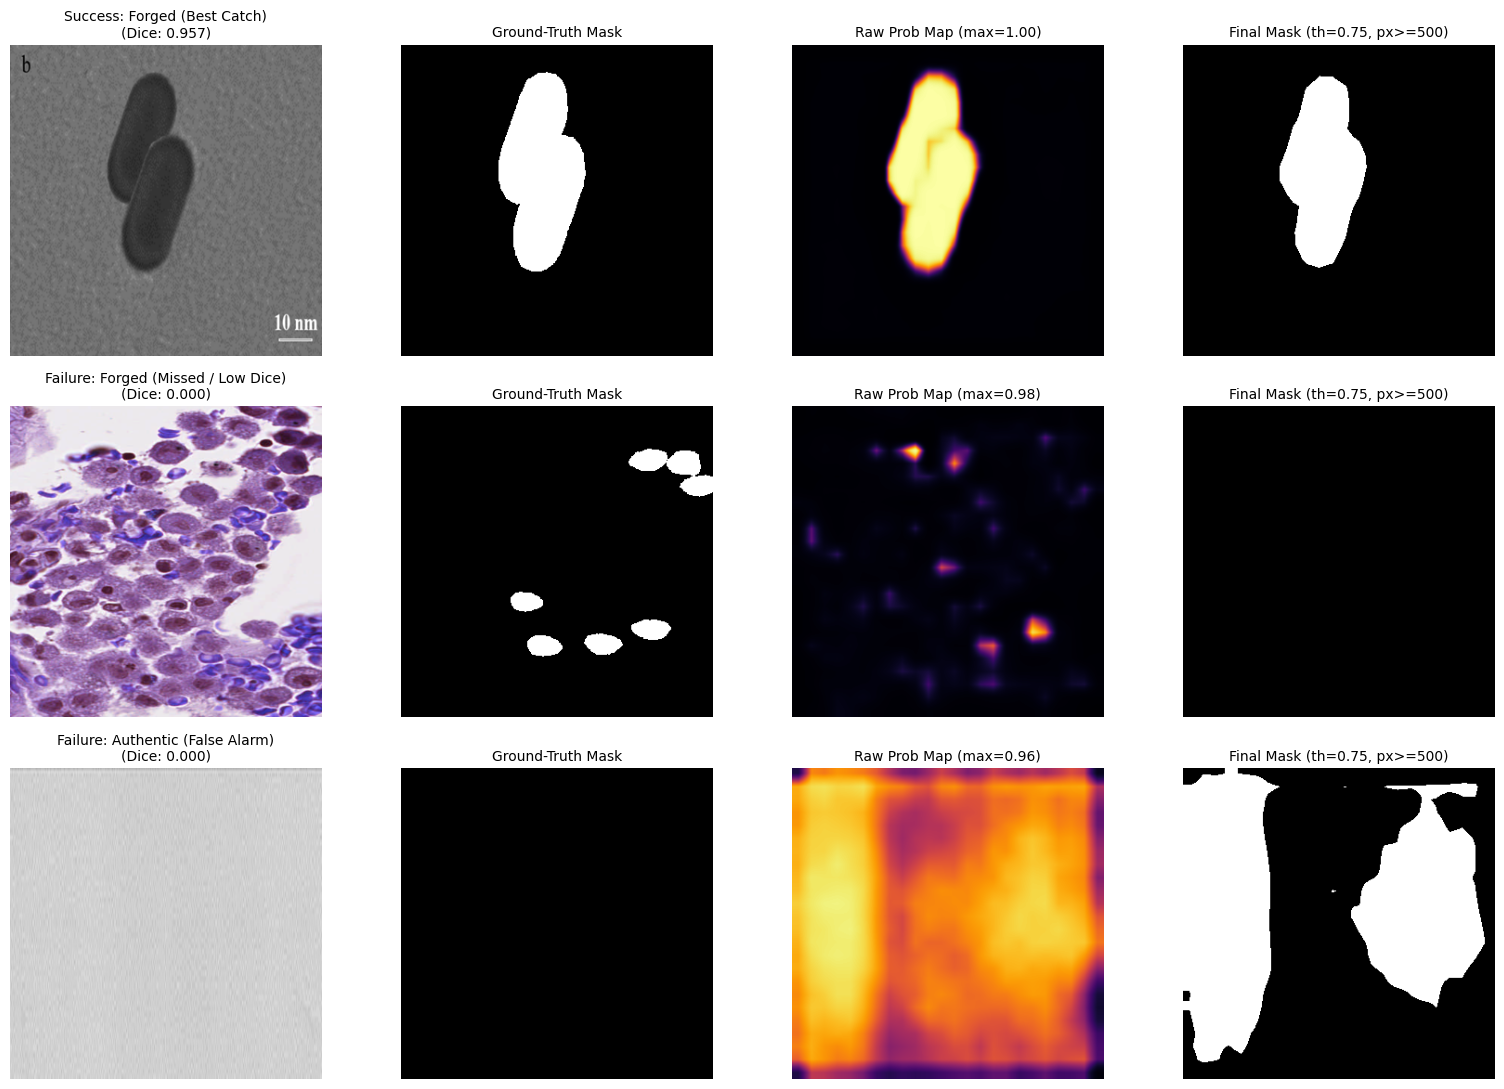

Saved visual error analysis to /kaggle/working/error_analysis.png


In [16]:
import matplotlib.pyplot as plt
ablation_df = pd.DataFrame(result_log)
ablation_df.to_csv("/kaggle/working/ablation_results.csv", index=False)
print("Saved ablation table to /kaggle/working/ablation_results.csv")

test_df_reset = test_df.reset_index(drop=True)

forged_scores = []  
auth_fp_areas = [] 

for i in range(len(test_probs)):
    pred_bin = (test_probs[i] >= best_thresh).astype(np.float32)
    if pred_bin.sum() < best_min_area:
        pred_bin[:] = 0.0

    if int(test_labels[i]) == 1:
        d, _ = compute_pixel_metrics(pred_bin, test_masks[i])
        forged_scores.append((i, d))
    else:
        auth_fp_areas.append((i, float(pred_bin.sum())))

best_forged_idx  = max(forged_scores, key=lambda x: x[1])[0]
worst_forged_idx = min(forged_scores, key=lambda x: x[1])[0]
worst_auth_idx   = max(auth_fp_areas, key=lambda x: x[1])[0]

cases = [
    (best_forged_idx,  "Success: Forged (Best Catch)"),
    (worst_forged_idx, "Failure: Forged (Missed / Low Dice)"),
    (worst_auth_idx,   "Failure: Authentic (False Alarm)"),
]

fig, axes = plt.subplots(3, 4, figsize=(16, 11))

for row_idx, (idx, title_prefix) in enumerate(cases):
    img_path = test_df_reset.loc[idx, "image_path"]
    orig_img = Image.open(img_path).convert("RGB").resize((IMG_SIZE_MOD, IMG_SIZE_MOD))

    true_mask = test_masks[idx]
    prob_map  = test_probs[idx]
    pred_bin  = (prob_map >= best_thresh).astype(np.float32)
    if pred_bin.sum() < best_min_area:
        pred_bin[:] = 0.0

    dice_val, _ = compute_pixel_metrics(pred_bin, true_mask)

    axes[row_idx, 0].imshow(orig_img)
    axes[row_idx, 0].set_title(f"{title_prefix}\n(Dice: {dice_val:.3f})", fontsize=10)

    axes[row_idx, 1].imshow(true_mask, cmap="gray", vmin=0, vmax=1)
    axes[row_idx, 1].set_title("Ground-Truth Mask", fontsize=10)

    axes[row_idx, 2].imshow(prob_map, cmap="inferno", vmin=0, vmax=1)
    axes[row_idx, 2].set_title(f"Raw Prob Map (max={prob_map.max():.2f})", fontsize=10)

    axes[row_idx, 3].imshow(pred_bin, cmap="gray", vmin=0, vmax=1)
    axes[row_idx, 3].set_title(f"Final Mask (th={best_thresh}, px>={best_min_area})", fontsize=10)

    for col_idx in range(4):
        axes[row_idx, col_idx].axis("off")

plt.tight_layout()
plt.savefig("/kaggle/working/error_analysis.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved visual error analysis to /kaggle/working/error_analysis.png")